In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os, json, time, random, shutil, warnings
from concurrent.futures import ThreadPoolExecutor
import numpy as np, pandas as pd, cv2, matplotlib.pyplot as plt, yaml
from scipy.optimize import linear_sum_assignment
from tqdm.auto import tqdm

warnings.filterwarnings('ignore', category=RuntimeWarning)
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

BASE_DIR = "/content/drive/MyDrive/lane detection"
DATA_DIR = f"{BASE_DIR}/data"
PROCESSED_DIR = f"{DATA_DIR}/processed"
LOCAL_PROCESSED = "/content/processed"
MODELS_DIR = f"{BASE_DIR}/models"
RESULTS_DIR = f"{BASE_DIR}/results"
FIGURES_DIR = f"{RESULTS_DIR}/figures"
PREDICTIONS_DIR = f"{BASE_DIR}/predictions"
RESULTS_CSV = f"{RESULTS_DIR}/results.csv"
for d in [LOCAL_PROCESSED, MODELS_DIR, RESULTS_DIR, FIGURES_DIR, PREDICTIONS_DIR]:
    os.makedirs(d, exist_ok=True)

W, H = 640, 224
DS = {'culane': dict(w=1640, h=590, crop=236), 'bdd': dict(w=1280, h=720, crop=302)}
LINE_WIDTH = {'culane': 30, 'bdd': round(30 * 1280 / 1640)}
SPLIT_DS = {'train': 'culane', 'val': 'culane', 'test_culane': 'culane', 'test_bdd': 'bdd'}

In [3]:
def load(name):
    src, dst = f"{PROCESSED_DIR}/{name}", f"{LOCAL_PROCESSED}/{name}"
    if not os.path.exists(f"{dst}/meta.csv"):
        shutil.copytree(src, dst, dirs_exist_ok=True)
    return np.load(f"{dst}/images.npy", mmap_mode='r'), np.load(f"{dst}/lanes.npy"), pd.read_csv(f"{dst}/meta.csv")

def resample(x, y):
    order = np.argsort(y)
    x, y = x[order], y[order]
    rows = np.arange(H)
    out = np.full(H, np.nan, np.float32)
    m = (rows >= y[0]) & (rows <= y[-1])
    out[m] = np.interp(rows[m], y, x)
    return out

def to_orig(lanes, ds):
    c = DS[ds]
    return lanes * c['w'] / W, np.arange(H) * (c['h'] - c['crop']) / H + c['crop']

def lane_poly(x, ds):
    xo, yo = to_orig(x, ds)
    m = np.isfinite(xo)
    return np.polyfit(yo[m], xo[m], 2) if m.sum() >= 3 else None

def draw(img, lanes, colors=((0, 255, 0), (255, 0, 0)), thickness=2):
    img = np.array(img)
    for x, color in zip(lanes, colors):
        m = np.isfinite(x)
        if m.sum() > 1:
            cv2.polylines(img, [np.stack([x[m], np.arange(H)[m]], 1).round().astype(np.int32)], False, color, thickness)
    return img

def ransac_poly(y, x, deg=2, iters=60, tol=3.0, min_inliers=10):
    rng = np.random.default_rng(SEED)
    if len(x) < max(deg + 1, min_inliers):
        return None, 0
    best = None
    for _ in range(iters):
        s = rng.choice(len(x), deg + 1, replace=False)
        if np.ptp(y[s]) < 1:
            continue
        inliers = np.abs(np.polyval(np.polyfit(y[s], x[s], deg), y) - x) < tol
        if best is None or inliers.sum() > best.sum():
            best = inliers
    if best is None or best.sum() < min_inliers:
        return None, 0
    return np.polyfit(y[best], x[best], deg), int(best.sum())

def hardware():
    cpu = next((l.split(':')[1].strip() for l in open('/proc/cpuinfo') if 'model name' in l), 'cpu')
    try:
        import torch
        gpu = torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'none'
    except Exception:
        gpu = 'none'
    return cpu, gpu

def log_result(**row):
    row = {'time': time.strftime('%Y-%m-%d %H:%M'), **row}
    df = pd.read_csv(RESULTS_CSV) if os.path.exists(RESULTS_CSV) else pd.DataFrame()
    pd.concat([df, pd.DataFrame([row])], ignore_index=True).to_csv(RESULTS_CSV, index=False)

def save_predictions(run, split, lanes, conf):
    d = f"{PREDICTIONS_DIR}/{run}"
    os.makedirs(d, exist_ok=True)
    np.savez_compressed(f"{d}/{split}.npz", lanes=lanes.astype(np.float32), conf=conf.astype(np.float32))

In [4]:
def lane_mask(x, ds):
    c = DS[ds]
    xo, yo = to_orig(x, ds)
    m = np.isfinite(xo)
    mask = np.zeros((c['h'] - c['crop'], c['w']), np.uint8)
    if m.sum() > 1:
        cv2.polylines(mask, [np.stack([xo[m], yo[m] - c['crop']], 1).round().astype(np.int32)], False, 1, LINE_WIDTH[ds])
    return mask

def iou(a, b):
    union = np.count_nonzero(a | b)
    return np.count_nonzero(a & b) / union if union else 0.0

def frame_ious(pred, gt, ds):
    pm = [lane_mask(x, ds) if np.isfinite(x).sum() > 1 else None for x in pred]
    gm = [lane_mask(x, ds) if np.isfinite(x).sum() > 1 else None for x in gt]
    side = [iou(p, g) if p is not None and g is not None else np.nan for p, g in zip(pm, gm)]
    P, G = [p for p in pm if p is not None], [g for g in gm if g is not None]
    matched = []
    if P and G:
        M = np.array([[iou(p, g) for g in G] for p in P])
        r, c = linear_sum_assignment(-M)
        matched = list(M[r, c])
    return dict(n_pred=len(P), n_gt=len(G), matched=matched, side=side,
                pred_on=[p is not None for p in pm], gt_on=[g is not None for g in gm])

def prf(tp, fp, fn):
    if tp + fp + fn == 0:
        return np.nan, np.nan, np.nan
    p = tp / (tp + fp) if tp + fp else 0.0
    r = tp / (tp + fn) if tp + fn else 0.0
    return p, r, 2 * p * r / (p + r) if p + r else 0.0

def score(records, thr):
    tp = sum(sum(m > thr for m in r['matched']) for r in records)
    n_pred, n_gt = sum(r['n_pred'] for r in records), sum(r['n_gt'] for r in records)
    out = dict(zip(['precision', 'recall', 'f1'], prf(tp, n_pred - tp, n_gt - tp)), fp=n_pred - tp)
    for k, s in enumerate(['left', 'right']):
        tps = sum(r['side'][k] > thr for r in records if np.isfinite(r['side'][k]))
        ps, gs = sum(r['pred_on'][k] for r in records), sum(r['gt_on'][k] for r in records)
        out[f'f1_{s}'] = prf(tps, ps - tps, gs - tps)[2]
    return out

def evaluate(pred_lanes, split, idx=None, thresholds=(0.5, 0.7)):
    _, gt_lanes, meta = load(split)
    ds = SPLIT_DS[split]
    idx = np.arange(len(meta)) if idx is None else np.asarray(idx)
    with ThreadPoolExecutor(8) as ex:
        records = list(tqdm(ex.map(lambda j: frame_ious(pred_lanes[j], gt_lanes[idx[j]], ds), range(len(idx))),
                            total=len(idx), desc=f'eval {split}', leave=False))
    cond = meta.condition.values[idx]
    rows = []
    for c in ['all'] + sorted(set(cond)):
        rec = [r for r, k in zip(records, cond) if c == 'all' or k == c]
        row = {'condition': c, 'n': len(rec)}
        for t in thresholds:
            s = score(rec, t)
            row.update(s if t == thresholds[0] else {f'f1@{t}': s['f1']})
        rows.append(row)
    return pd.DataFrame(rows).set_index('condition'), records

In [5]:
images_val, lanes_val, meta_val = load('val')
idx = np.arange(2000)
gt = lanes_val[idx]
shift = lambda px: gt + px * W / DS['culane']['w']
no_left = gt.copy()
no_left[:, 0] = np.nan
tests = {
    'ground truth': gt,
    'shifted 5 px': shift(5),
    'shifted 10 px': shift(10),
    'shifted 20 px': shift(20),
    'left removed': no_left,
    'left/right swapped': gt[:, ::-1],
    'empty': np.full_like(gt, np.nan),
}
sanity = pd.DataFrame({k: evaluate(v, 'val', idx)[0].loc['all'] for k, v in tests.items()}).T
display(sanity[['precision', 'recall', 'f1', 'f1@0.7', 'f1_left', 'f1_right']].round(3))

eval val:   0%|          | 0/2000 [00:00<?, ?it/s]

eval val:   0%|          | 0/2000 [00:00<?, ?it/s]

eval val:   0%|          | 0/2000 [00:00<?, ?it/s]

eval val:   0%|          | 0/2000 [00:00<?, ?it/s]

eval val:   0%|          | 0/2000 [00:00<?, ?it/s]

eval val:   0%|          | 0/2000 [00:00<?, ?it/s]

eval val:   0%|          | 0/2000 [00:00<?, ?it/s]

,precision,recall,f1,f1@0.7,f1_left,f1_right
ground truth,1.000,1.000,1.000,1.000,1.000,1.000
shifted 5 px,1.000,1.000,1.000,1.000,1.000,1.000
shifted 10 px,1.000,1.000,1.000,0.305,1.000,1.000
shifted 20 px,0.225,0.225,0.225,0.002,0.093,0.357
left removed,1.000,0.499,0.666,0.666,0.000,1.000
left/right swapped,1.000,1.000,1.000,1.000,0.000,0.000
empty,0.000,0.000,0.000,0.000,0.000,0.000


trapezoid: [[308.3999938964844, 44.0], [337.3999938964844, 44.0], [399.79998779296875, 107.0], [264.20001220703125, 107.0]]


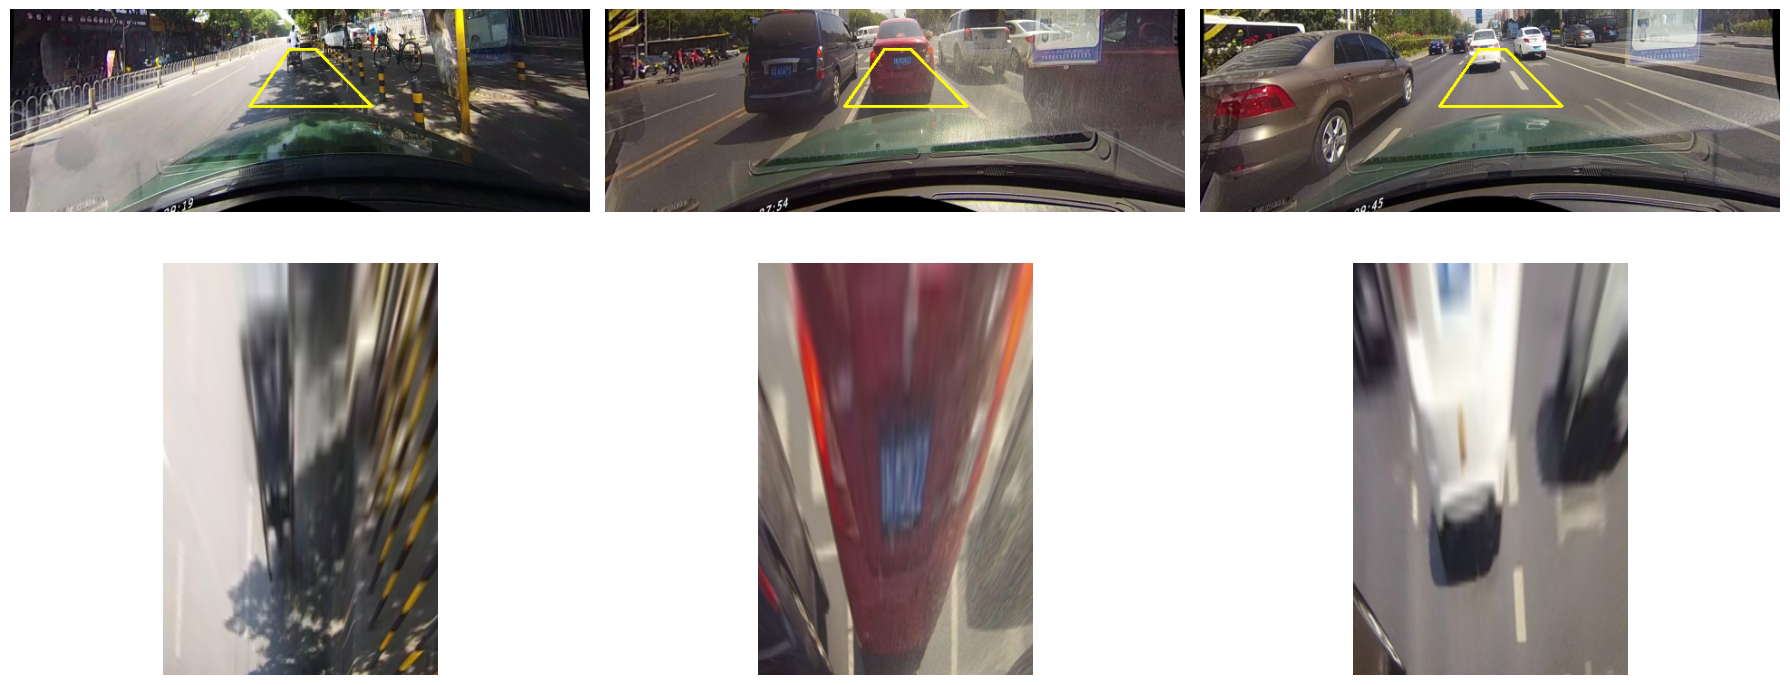

In [6]:
Y_TOP, Y_BOT = int(0.2 * H), int(0.48 * H)
BW, BH = 320, 480
left_med, right_med = np.nanmedian(lanes_val[:, 0], 0), np.nanmedian(lanes_val[:, 1], 0)
SRC = np.float32([[left_med[Y_TOP], Y_TOP], [right_med[Y_TOP], Y_TOP], [right_med[Y_BOT], Y_BOT], [left_med[Y_BOT], Y_BOT]])
DST = np.float32([[0.3 * BW, 0], [0.7 * BW, 0], [0.7 * BW, BH], [0.3 * BW, BH]])
M_BEV, M_INV = cv2.getPerspectiveTransform(SRC, DST), cv2.getPerspectiveTransform(DST, SRC)
print('trapezoid:', SRC.round(1).tolist())

plt.figure(figsize=(18, 8))
for j, i in enumerate(np.random.default_rng(1).choice(len(meta_val), 3, replace=False)):
    img = np.array(images_val[i])
    plt.subplot(2, 3, j + 1)
    plt.imshow(cv2.polylines(img.copy(), [SRC.astype(np.int32)], True, (255, 255, 0), 2))
    plt.axis('off')
    plt.subplot(2, 3, j + 4)
    plt.imshow(cv2.warpPerspective(img, M_BEV, (BW, BH)))
    plt.axis('off')
plt.tight_layout()
plt.show()

In [7]:
BASE_PARAMS = dict(sobel=30, s=120, dl=15, windows=9, margin=25, minpix=15, min_conf=0.4, tol=4.0)

def binary_mask(bev_rgb, p):
    hls = cv2.cvtColor(bev_rgb, cv2.COLOR_RGB2HLS)
    l, s = hls[..., 1].astype(np.float32), hls[..., 2]
    sx = np.abs(cv2.Sobel(l, cv2.CV_32F, 1, 0, ksize=3))
    sx = 255 * sx / (sx.max() + 1e-6)
    bright = l > cv2.blur(l, (31, 31)) + p['dl']
    return (((sx > p['sobel']) | (s > p['s'])) & bright).astype(np.uint8)

def baseline_predict(img, p=BASE_PARAMS):
    bev = binary_mask(cv2.warpPerspective(np.asarray(img), M_BEV, (BW, BH)), p)
    bev = cv2.morphologyEx(bev, cv2.MORPH_OPEN, np.ones((3, 3), np.uint8))
    ys, xs = bev.nonzero()
    hist = bev[BH // 2:].sum(0)
    lanes, conf = np.full((2, H), np.nan, np.float32), np.zeros(2, np.float32)
    wh = BH // p['windows']
    for k, (lo, hi) in enumerate([(0, BW // 2), (BW // 2, BW)]):
        if hist[lo:hi].max() == 0:
            continue
        x_cur, keep, hits = lo + int(np.argmax(hist[lo:hi])), [], 0
        for w in range(p['windows']):
            sel = np.where((ys >= BH - (w + 1) * wh) & (ys < BH - w * wh) & (np.abs(xs - x_cur) < p['margin']))[0]
            keep.append(sel)
            if len(sel) >= p['minpix']:
                x_cur, hits = int(xs[sel].mean()), hits + 1
        conf[k] = hits / p['windows']
        keep = np.concatenate(keep)
        if conf[k] < p['min_conf']:
            continue
        coef, _ = ransac_poly(ys[keep].astype(np.float32), xs[keep].astype(np.float32), 2, tol=p['tol'])
        if coef is None:
            continue
        yb = np.linspace(0, BH - 1, 60, dtype=np.float32)
        pts = cv2.perspectiveTransform(np.stack([np.polyval(coef, yb), yb], 1)[None].astype(np.float32), M_INV)[0]
        x = resample(pts[:, 0], pts[:, 1])
        low = pts[pts[:, 1] > Y_TOP + 0.6 * (Y_BOT - Y_TOP)]
        k1, b1 = np.polyfit(low[:, 1], low[:, 0], 1)
        x[Y_BOT:] = k1 * np.arange(Y_BOT, H) + b1
        x[:Y_TOP] = np.nan
        x[(x < -W) | (x > 2 * W)] = np.nan
        lanes[k] = x
    return lanes, conf

def predict_split(images, idx, p=BASE_PARAMS):
    out = [baseline_predict(images[i], p) for i in idx]
    return np.stack([o[0] for o in out]), np.stack([o[1] for o in out])

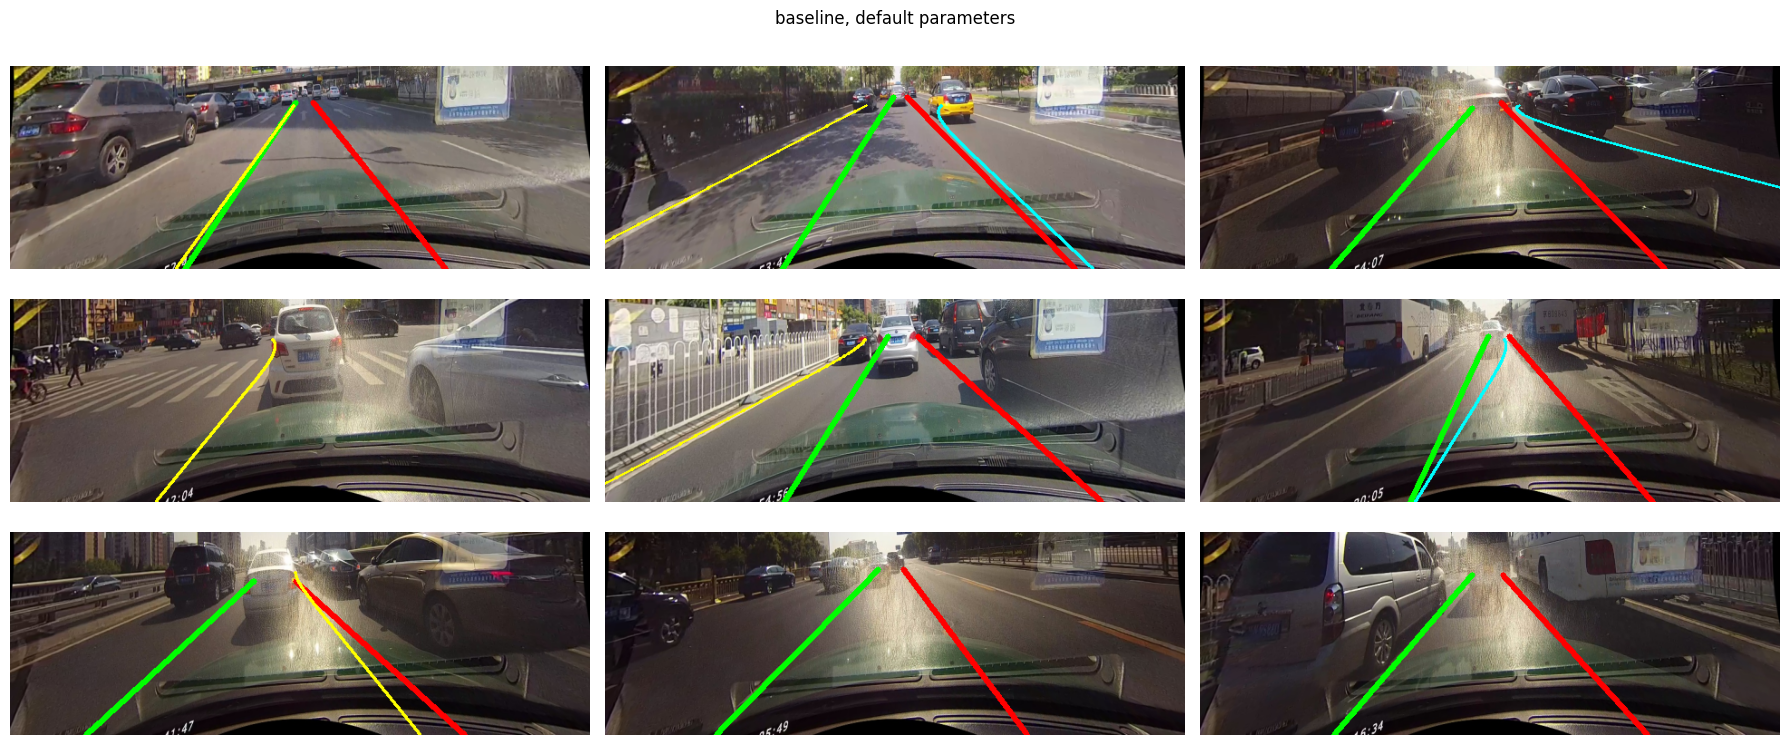

In [8]:
def show_pred(images, gt, pred, idx, title, path=None):
    rows = (len(idx) + 2) // 3
    plt.figure(figsize=(18, 2.6 * rows))
    for j, i in enumerate(idx):
        img = draw(images[i], gt[i], thickness=6)
        img = draw(img, pred[j] if len(pred) == len(idx) else pred[i], colors=((255, 255, 0), (0, 255, 255)), thickness=2)
        plt.subplot(rows, 3, j + 1)
        plt.imshow(img)
        plt.axis('off')
    plt.suptitle(title)
    plt.tight_layout()
    if path:
        plt.savefig(path, dpi=120, bbox_inches='tight')
    plt.show()

check_idx = np.random.default_rng(SEED).choice(len(meta_val), 9, replace=False)
pred_check, _ = predict_split(images_val, check_idx)
show_pred(images_val, lanes_val, pred_check, check_idx, 'baseline, default parameters')

In [9]:
tune_idx = np.sort(np.random.default_rng(SEED).choice(len(meta_val), 1500, replace=False))
grid = [dict(BASE_PARAMS, sobel=a, s=b, dl=d) for a in (20, 40) for b in (100, 150) for d in (10, 20, 30)]
scores = []
for p in tqdm(grid, desc='grid'):
    pred, _ = predict_split(images_val, tune_idx, p)
    table, _ = evaluate(pred, 'val', tune_idx)
    scores.append(dict(sobel=p['sobel'], s=p['s'], dl=p['dl'], f1=table.loc['all', 'f1'], f1_07=table.loc['all', 'f1@0.7']))
scores = pd.DataFrame(scores).sort_values('f1', ascending=False)
display(scores.round(4))
best = scores.iloc[0]
BEST_PARAMS = dict(BASE_PARAMS, sobel=int(best.sobel), s=int(best.s), dl=int(best.dl))
print('best:', BEST_PARAMS)

grid:   0%|          | 0/12 [00:00<?, ?it/s]

eval val:   0%|          | 0/1500 [00:00<?, ?it/s]

eval val:   0%|          | 0/1500 [00:00<?, ?it/s]

eval val:   0%|          | 0/1500 [00:00<?, ?it/s]

eval val:   0%|          | 0/1500 [00:00<?, ?it/s]

eval val:   0%|          | 0/1500 [00:00<?, ?it/s]

... (5 outputs left out)

eval val:   0%|          | 0/1500 [00:00<?, ?it/s]

eval val:   0%|          | 0/1500 [00:00<?, ?it/s]

,sobel,s,dl,f1,f1_07
1,20,100,20,0.1443,0.0888
0,20,100,10,0.1434,0.0853
3,20,150,10,0.1321,0.0674
2,20,100,30,0.1239,0.0870
4,20,150,20,0.1184,0.0692
6,40,100,10,0.1155,0.0692
7,40,100,20,0.1146,0.0738
5,20,150,30,0.0980,0.0670
8,40,100,30,0.0969,0.0727
9,40,150,10,0.0850,0.0461


best: {'sobel': 20, 's': 100, 'dl': 20, 'windows': 9, 'margin': 25, 'minpix': 15, 'min_conf': 0.4, 'tol': 4.0}


In [10]:
if os.path.exists(RESULTS_CSV):
    old = pd.read_csv(RESULTS_CSV)
    old[old.run != 'baseline'].to_csv(RESULTS_CSV, index=False)

pred_val, conf_val = predict_split(images_val, range(len(meta_val)), BEST_PARAMS)
table_val, records_val = evaluate(pred_val, 'val')
display(table_val.round(3))

for i in range(20):
    baseline_predict(images_val[i], BEST_PARAMS)
t = time.perf_counter()
for i in range(500):
    baseline_predict(images_val[i], BEST_PARAMS)
ms = (time.perf_counter() - t) / 500 * 1000
cpu, gpu = hardware()
print(f'{ms:.2f} ms/frame on {cpu}')

run_dir = f"{MODELS_DIR}/baseline"
os.makedirs(run_dir, exist_ok=True)
yaml.safe_dump({'params': BEST_PARAMS, 'src': SRC.tolist(), 'dst': DST.tolist(), 'bev_size': [BW, BH], 'y_top': Y_TOP, 'y_bot': Y_BOT, 'input': [W, H]}, open(f"{run_dir}/config.yaml", 'w'))
json.dump({**table_val.loc['all'].to_dict(), 'ms_per_frame': ms, 'hardware': cpu}, open(f"{run_dir}/metrics.json", 'w'), indent=2, default=float)
log_result(run='baseline', detector='classical', backbone='none', tracker='none', split='val', resolution=f'{W}x{H}',
           params=0, ms_per_frame=round(ms, 2), device='cpu', hardware=cpu, **table_val.loc['all'].round(4).to_dict())

eval val:   0%|          | 0/9500 [00:00<?, ?it/s]

,n,precision,recall,f1,fp,f1_left,f1_right,f1@0.7
condition,,,,,,,,
all,9500,0.193,0.112,0.142,8217,0.135,0.146,0.087
unknown,9500,0.193,0.112,0.142,8217,0.135,0.146,0.087


14.08 ms/frame on AMD EPYC 7B12


/tmp/ipykernel_613/758030574.py:61: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  pd.concat([df, pd.DataFrame([row])], ignore_index=True).to_csv(RESULTS_CSV, index=False)


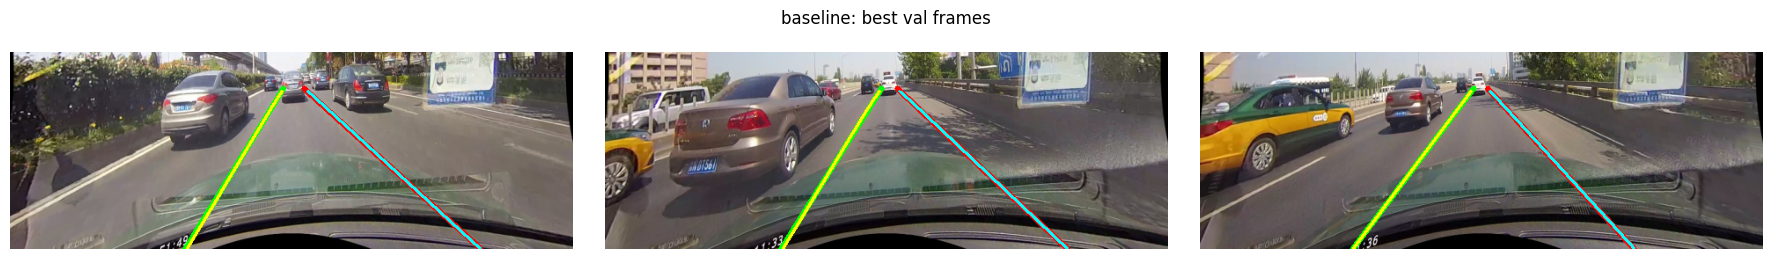

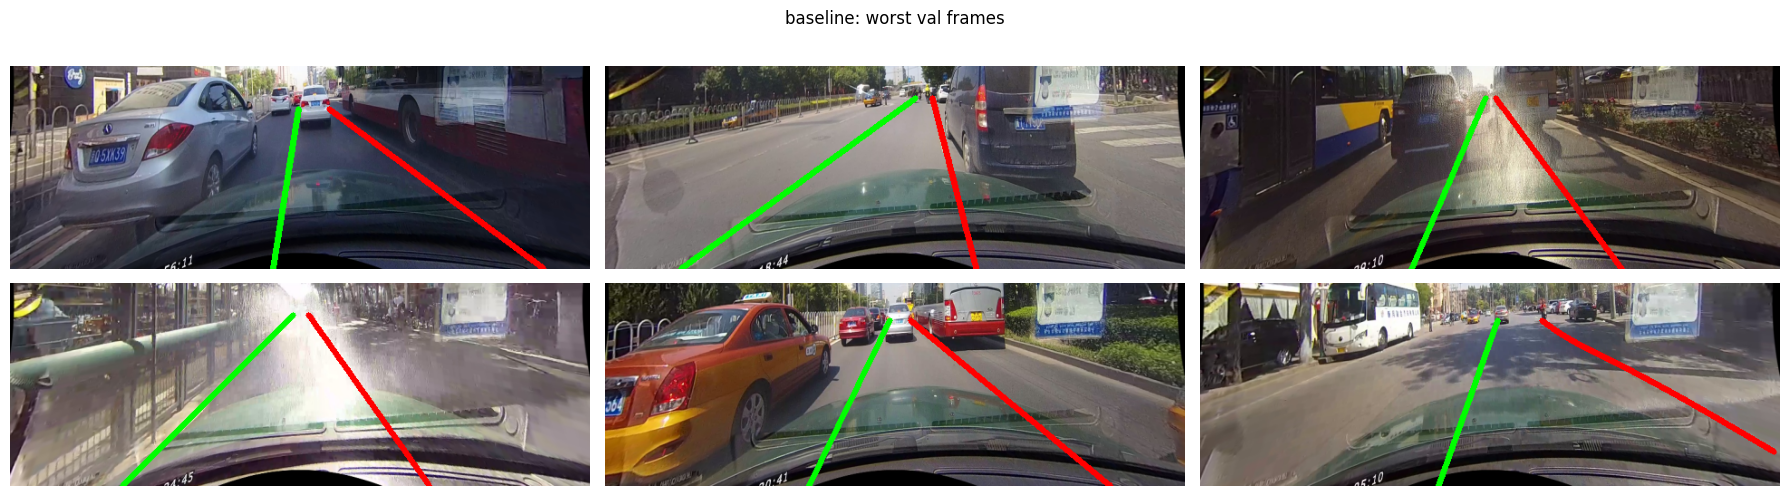

In [11]:
side_iou = np.array([np.nan_to_num(r['side']).mean() for r in records_val])
has_gt = np.array([any(r['gt_on']) for r in records_val])
order = [i for i in np.argsort(side_iou) if has_gt[i]]
show_pred(images_val, lanes_val, pred_val, order[-3:], 'baseline: best val frames', f"{FIGURES_DIR}/baseline_best.png")
show_pred(images_val, lanes_val, pred_val, order[:6], 'baseline: worst val frames', f"{FIGURES_DIR}/baseline_worst.png")

In [12]:
for split in ['test_culane', 'test_bdd']:
    images, _, meta = load(split)
    lanes, conf = predict_split(images, range(len(meta)), BEST_PARAMS)
    save_predictions('baseline', split, lanes, conf)
    print(split, 'saved', lanes.shape)

test_culane saved (3798, 2, 224)
test_bdd saved (2560, 2, 224)
